In [1]:
# Multivariate Regression
# z = X @ m + c  
# y_pred = 1 / (1 + e^(-z))
# Loss = -(1/n) * summation( y * log(y_pred) + (1 - y) * log(1 - y_pred) )
# error = y_pred - y
# dE/dm = (1/n) * (X.T @ error)
# dE/dc = (1/n) * summation(error)
# m = m - L * dE/dm
# c = c - L * dE/dc
# If y_pred >= 0.5: predict Class 1
# If y_pred < 0.5:  predict Class 0

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_breast_cancer
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

In [3]:
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

In [4]:
# sns.pairplot(df)

<Axes: >

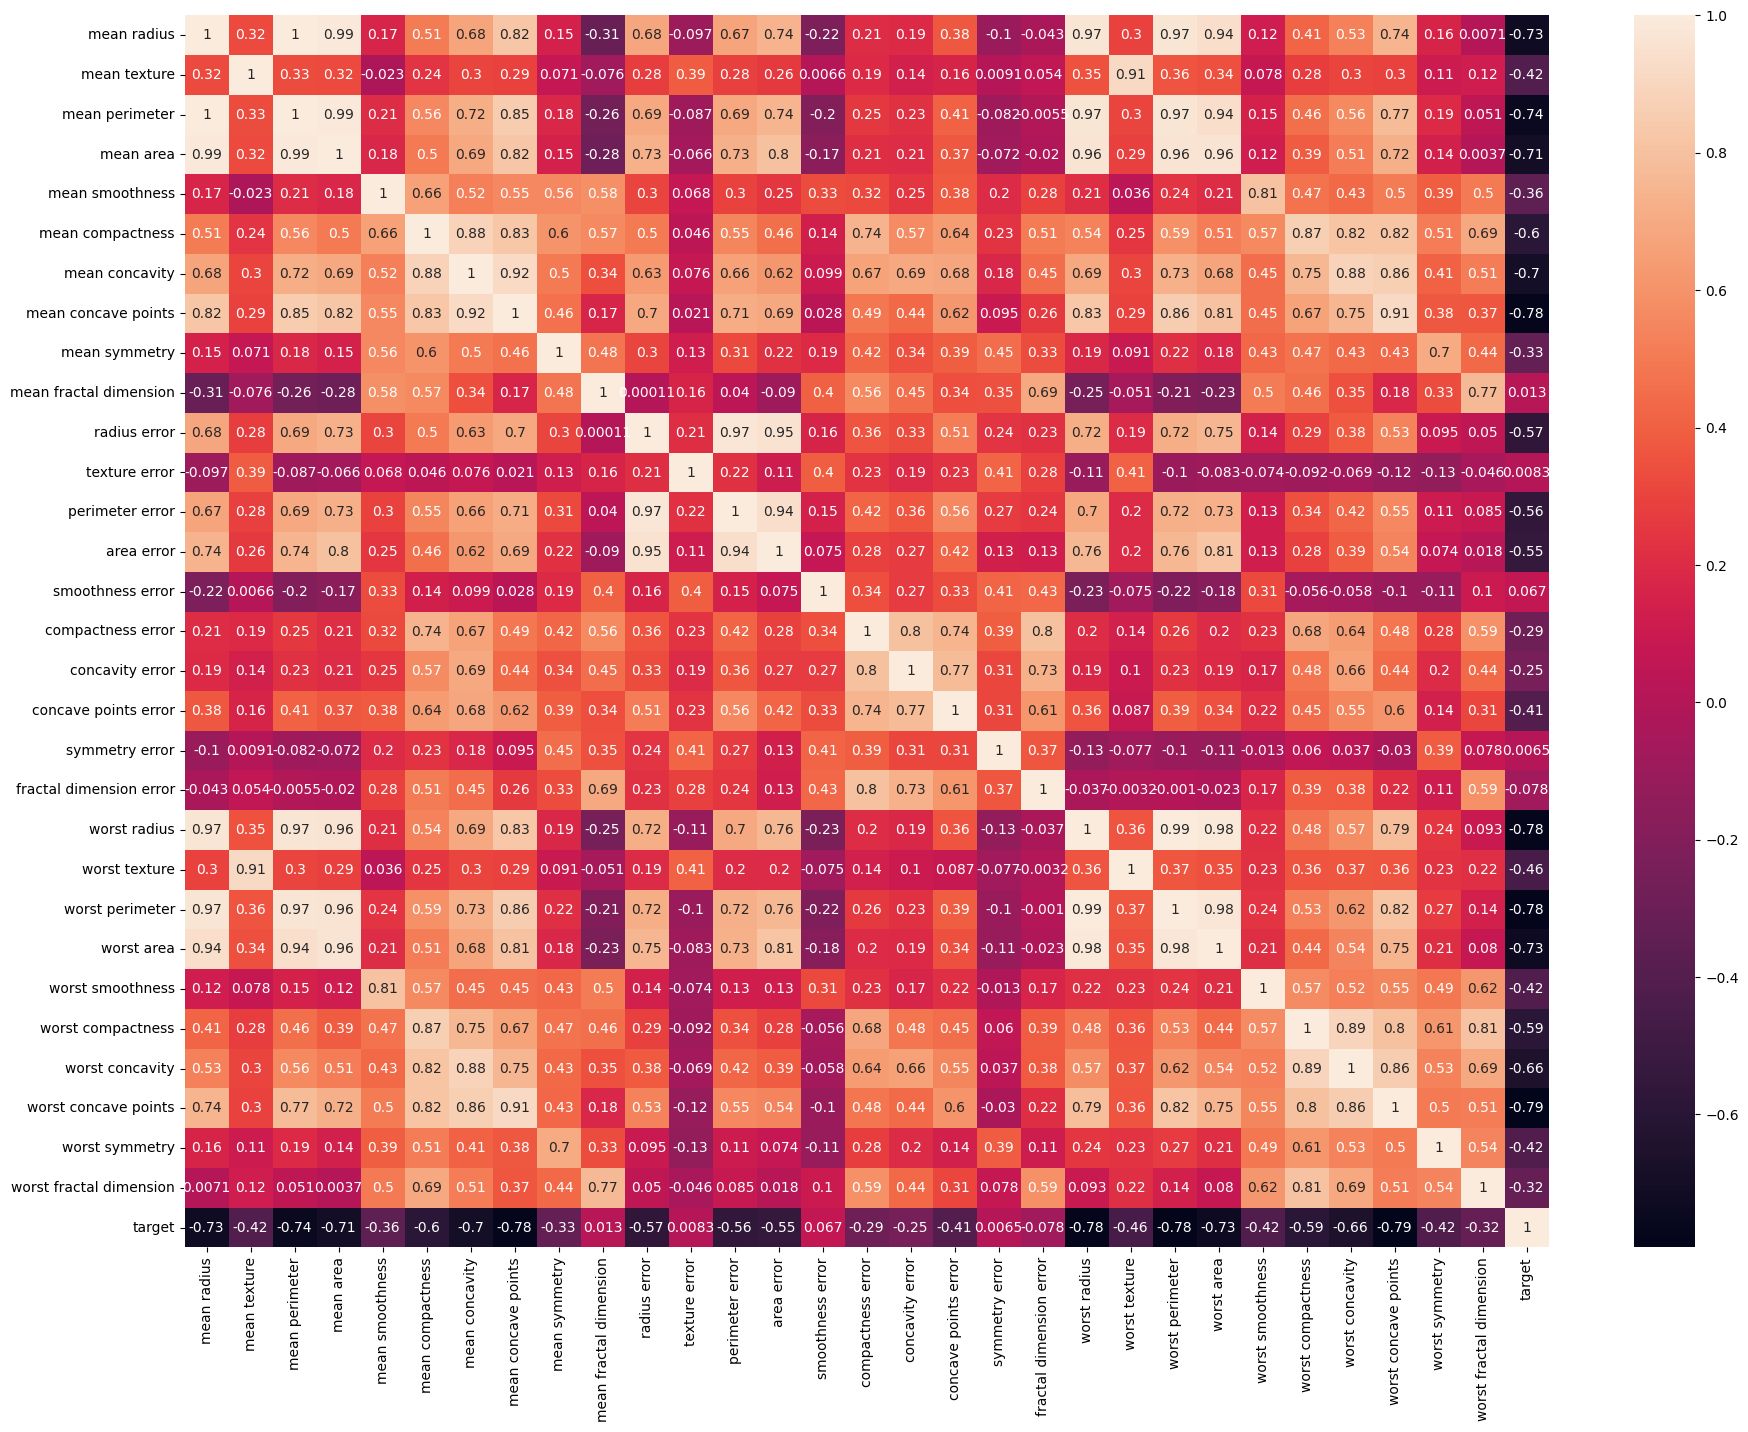

In [5]:
plt.figure(figsize=(22,16))
sns.heatmap(df.corr(),annot=True)

In [6]:
X = df.drop(['target'], axis=1)
y = df['target'].values
X = ((X - X.mean()) / X.std()).values

In [7]:
def sigmoid_function(z):
    #z = np.clip(z, -500, 500) 
    return 1/(1+np.exp(-z))

In [8]:
# We can't use MSE here because passing the linear output through a sigmoid makes the MSE curve non-convex. 
# It creates a "wavy" surface with many local minima, so gradient descent gets stuck. 
# Binary Cross-Entropy (Log Loss) is convex, guaranteeing a single global minimum.

In [9]:
def gradient_descent(m,c,L,X,y):
    n=len(X)
    z=np.dot(X,m)+c
    y_pred=sigmoid_function(z)
    eps = 1e-15
    y_pred = np.clip(y_pred, eps, 1 - eps)
    Loss = -(1/n) * np.sum(y * np.log(y_pred) + (1 - y) * np.log(1 - y_pred))
    error = y_pred - y
    m_gradient = (1/n) * np.dot(X.T,error)
    c_gradient = (1/n) * np.sum(error)
    m = m - L * m_gradient
    c = c - L * c_gradient
    return m,c,Loss   

In [10]:
m = np.zeros(X.shape[1])
c=0
L=0.1
epoch=4000
losses=[]

In [11]:
for _ in range(epoch):
    m,c,Loss=gradient_descent(m,c,L,X,y)
    losses.append(Loss)

In [12]:
print(m,'\n',c)

[-0.48060938 -0.56496628 -0.4558643  -0.56751275 -0.20248693  0.61184617
 -0.93913466 -1.03657434  0.11622437  0.44037003 -1.50270911  0.26632921
 -0.9094661  -1.13871343 -0.29577219  1.01105225  0.00363527 -0.35926079
  0.38325516  0.81971345 -1.1750452  -1.46105044 -0.97304669 -1.14559191
 -0.94330595  0.02882056 -1.07154823 -1.14632527 -1.10207164 -0.48560476] 
 0.22209417136048318


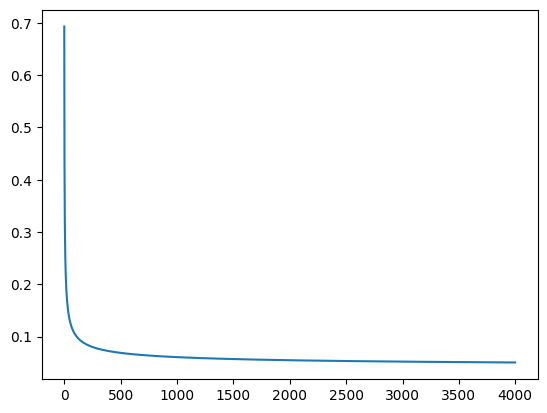

In [13]:
plt.plot(range(epoch),losses)

In [14]:
z_final = np.dot(X, m) + c
y_pred_prob = sigmoid_function(z_final)
y_pred_class = (y_pred_prob >= 0.5).astype(int)
accuracy = np.mean(y_pred_class == y)
print(f"Accuracy: {accuracy * 100:.2f}")

Accuracy: 98.77


In [15]:
sk_model = LogisticRegression(max_iter=10000) 
sk_model.fit(X, y)

print(f"Scratch: {c:.5f}")
print(f"Sklearn: {sk_model.intercept_[0]:.5f}\n")

print("--- Coefficients (m) ---")
print(f"Scratch: {m} \n \n Sklearn: {sk_model.coef_[0]}")

Scratch: 0.22209
Sklearn: 0.21960

--- Coefficients (m) ---
Scratch: [-0.48060938 -0.56496628 -0.4558643  -0.56751275 -0.20248693  0.61184617
 -0.93913466 -1.03657434  0.11622437  0.44037003 -1.50270911  0.26632921
 -0.9094661  -1.13871343 -0.29577219  1.01105225  0.00363527 -0.35926079
  0.38325516  0.81971345 -1.1750452  -1.46105044 -0.97304669 -1.14559191
 -0.94330595  0.02882056 -1.07154823 -1.14632527 -1.10207164 -0.48560476] 
 
 Sklearn: [-0.37524337 -0.38042681 -0.36084782 -0.43968798 -0.16611503  0.56231124
 -0.85671043 -0.96490203  0.07670663  0.32677312 -1.28938429  0.26690815
 -0.66913188 -1.00034038 -0.28054658  0.74295934  0.10196824 -0.32345394
  0.29421814  0.67936433 -1.02860478 -1.32331957 -0.8214345  -0.99716083
 -0.66422283  0.05307726 -0.87860204 -0.9244467  -0.88773021 -0.4877152 ]


In [16]:
# Putting penalty=None in LogisticRegression Function, which is saying no to regularisation (L2), weights explodes to massive numbers.

# Reason: The Breast Cancer dataset is nearly perfectly separable. The loss function wants to push the weights 
# to infinity to make the sigmoid output exactly 0 or 1. 
# Multicollinearity makes this worse because multiple weights can grow infinitely while canceling each other out.
# L2 Regularization acts as a leash, forcing the weights to stay small and stable.
# In production, unregularized weights like this are dangerous, they make the model highly sensitive to new data and lead to garbage predictions.

# Why didn't the Scratch Model Explode? 
# Because of "Early Stopping". We started our weights at exactly 0 and only ran 4000 epochs with a learning rate of 0.1. 
# Gradient descent takes tiny steps. It found a "good enough" spot long before the weights had time to grow to infinity.
# This is a very common form of implicit regularization in Machine Learning (especially Deep Learning). 
# By stopping the training loop early, we inadvertently kept the weights small and stable.


In [17]:
# Metrics

# Confusion Matrix (TP, TN, FP, FN) : mindmap or a evaluation matrix for classifications.
# Accuracy : What proportion is correctly classified/predicted
# Precision : How often do we get correct classifications. Out of all the times the model guessed Positive, how many were actually right
# Recall (Sensitivity) : It is the percentage of actual positives correctly classified/predicted.
# Specificity : It is the percentage of actual negatives correctly classified/predicted.
# F1-Score : To balance Recall and Precision

# Sometimes Accuracy is garbage...like when there is a class imbalance
# In some cases, like medical examples, False negatives are costly. So Recall/Sensitivity is prioritized
# If False Positives are costly, prioritize Specificity.

# Here, 0 = Malignant (Cancer), 1 = Benign (Healthy). So False Positives are costly. So  Specificity is prioritized

In [18]:
y_pred=np.dot(X,m)+c
y_pred_prob = sigmoid_function(y_pred)
y_pred_class=(y_pred_prob>=0.5).astype('int')

In [19]:
TP=np.sum((y_pred_class==1) & (y==1))
TN=np.sum((y_pred_class==0) & (y==0))
FP=np.sum((y_pred_class==1) & (y==0))
FN=np.sum((y_pred_class==0) & (y==1))

In [20]:
Accuracy=(TP+TN)/(TP+TN+FP+FN)
Precision = TP/(TP+FP)
Recall = Sensitivity = TP/(TP+FN)
Specificity = TN/(TN+FP)
F1_score= (2 * Precision * Recall )/(Precision + Recall)

print(f'Accuracy : {Accuracy:.2f}\n Precision : {Precision:.2f} \n Recall : {Recall:.2f} \n Specificity : {Specificity:.2f} \n F1_Score : {F1_score:.2f}')

Accuracy : 0.99
 Precision : 0.99 
 Recall : 0.99 
 Specificity : 0.98 
 F1_Score : 0.99


In [21]:
# So far, we used our entire data in training the model (estimating the parameters). 
# This gives an optimistic, inflated score and does not prove generalization.

# Earlier, we scaled the data BEFORE splitting. 
# This can lead to Data Leakage, as the test set's mean/variance influences the training process.

# Below, we fix this by splitting the data first, and calculating the scaler only on the training set.

In [22]:
X=df.drop(['target'],axis=1).values
y=df['target'].values


X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2, random_state=42, stratify=y)

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std

In [23]:
m = np.zeros(X_train_scaled.shape[1])
c=0
L=0.1
epoch=4000
losses=[]

In [24]:
for _ in range(epoch):
    m,c,Loss=gradient_descent(m,c,L,X_train_scaled,y_train)
    losses.append(Loss)

In [25]:
print(m,'\n',c)

[-0.61033224 -0.74818846 -0.56080384 -0.67604504 -0.26746823  0.78119404
 -0.69134605 -0.81047543 -0.16033661  0.35994103 -1.35273445  0.31170584
 -0.77491819 -1.14318626 -0.22315932  0.92840945  0.08318584 -0.51134165
  0.47092745  0.6535369  -1.1699788  -1.53856223 -0.96881913 -1.1798838
 -1.07696529  0.07239574 -1.0242229  -1.2012014  -1.25388465 -0.21229118] 
 0.27435785386444755


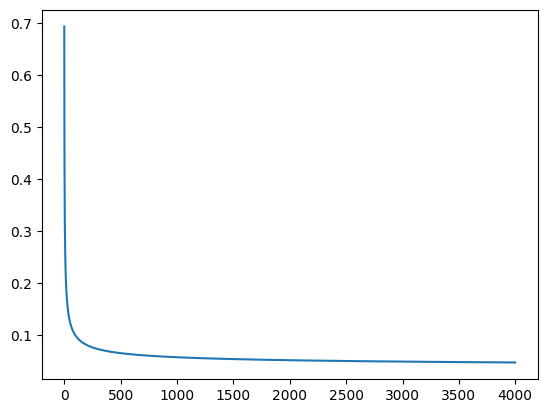

In [26]:
plt.plot(range(epoch),losses)

In [27]:
y_pred=np.dot(X_test_scaled,m)+c
y_pred_prob = sigmoid_function(y_pred)
y_pred_class=(y_pred_prob>=0.5).astype('int')

In [28]:
TP=np.sum((y_pred_class==1) & (y_test==1))
TN=np.sum((y_pred_class==0) & (y_test==0))
FP=np.sum((y_pred_class==1) & (y_test==0))
FN=np.sum((y_pred_class==0) & (y_test==1))

In [29]:
Accuracy=(TP+TN)/(TP+TN+FP+FN)
Precision = TP/(TP+FP)
Recall = Sensitivity = TP/(TP+FN)
Specificity = TN/(TN+FP)
F1_score= (2 * Precision * Recall )/(Precision + Recall)

print(f'Accuracy : {Accuracy:.2f}\n Precision : {Precision:.2f} \n Recall : {Recall:.2f} \n Specificity : {Specificity:.2f} \n F1_Score : {F1_score:.2f}')

Accuracy : 0.97
 Precision : 0.99 
 Recall : 0.97 
 Specificity : 0.98 
 F1_Score : 0.98


In [30]:
print("Sklearn Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_class))

print(f"\nYour TP: {TP}, TN: {TN}, FP: {FP}, FN: {FN}")

sk_model = LogisticRegression(max_iter=10000)
sk_model.fit(X_train_scaled, y_train)
sk_preds = sk_model.predict(X_test_scaled)

agreement = np.mean(sk_preds == y_pred_class) * 100
print(f"\nAgreement between Scratch and Sklearn: {agreement:.2f}%")

Sklearn Confusion Matrix:
[[41  1]
 [ 2 70]]

Your TP: 70, TN: 41, FP: 1, FN: 2

Agreement between Scratch and Sklearn: 99.12%


In [31]:
# OBSERVATION:
    # Out of 42 actual malignant cases (0), we missed 1 (FP = 1). This is a costly error, but our specificity is still 41/42 = 97.6%.
    # We had 2 False Negatives (FN = 2), meaning 2 benign cases were flagged as malignant. These are false alarms and are much less costly here.
    # The 99% metrics calculated earlier were on the training set. These 97% metrics are the better estimate of how the model will perform on unseen patients.

In [32]:
# Final Note

# We split the data 80/20. The dataset has 569 rows. So the test set has ~114 rows.
# If the test accuracy is 97%, that means we got roughly 3 rows wrong out of 114. If we had gotten just 1 more row wrong, our accuracy would drop to 96%.

# This means a single random split might be "lucky" or "unlucky".

# When we get to Cross-Validation (K-Fold), we will split the data 5/10 times (5/10-fold CV), train 5 different models, and average the scores. 
# This removes the "luck" of a single split.